# 07 · Storage tier: KV spill and retrieve, and the spill decision

The coalescing cost model fitted to the Update 6 NVMe sweep, the functional checks (alignment, free list, CRC), the PMP three-option spill choice, and a coalescing sweep through StorageTier.

**README sections covered:** [12. NVMe storage tier](../docs/explained/12-storage-tier.md), [10. PMP bang-bang controller: hot, cold or spill](../docs/explained/10-pmp-controller.md)

Figures are written to `docs/figures/` (model figures: arithmetic, proofs and repo results) and `docs/figures/<MODE>/` (measured on the machine that ran the notebook).

In [1]:
MODE = "local"            # "local" | "cluster"
RESULTS_SUBDIR = "storage_tier"
SPILL_DIR = "/tmp/scuffed-spill" if MODE == "local" else "/mnt/nvme/scuffed-spill"   # cluster: a directory on the NVMe under test
O_DIRECT = MODE == "cluster"
FSYNC = True
BLOCK_KB = 64 if MODE == "local" else 1568          # 1568 KiB matches the Update 6 block (3-bit, 256 tokens, 32 heads, dim 128, unpacked)
BLOCK_SIZES_KB = [16, 64] if MODE == "local" else [256, 1568, 4096]
COALESCE = [1, 2, 5, 10, 20, 50]
BATCHES = 5 if MODE == "local" else 50

In [2]:
import os, sys, json, socket, subprocess, time
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "middleware").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
HOST = socket.gethostname()
STAMP = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
RESULTS = (ROOT / "benchmarks" / "results" / RESULTS_SUBDIR) if MODE == "cluster" else Path("/tmp/scuffed-local") / RESULTS_SUBDIR
RESULTS.mkdir(parents=True, exist_ok=True)
FIGDIR = ROOT / "docs" / "figures"
(FIGDIR / MODE).mkdir(parents=True, exist_ok=True)

import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.4,
    "lines.markersize": 4, "figure.constrained_layout.use": False})
C = {"hot": "#f97316", "cold": "#38bdf8", "spill": "#a78bfa", "ok": "#34d399", "bad": "#f43f5e",
     "gold": "#facc15", "ink": "#1f2937", "muted": "#94a3b8"}

def fig(name, model=False, caption=None, f=None):
    """Save the current figure as PNG + PDF and show it.
    model=True: arithmetic or repo results, same on every machine -> docs/figures/<name>
    model=False: measured on this machine -> docs/figures/<MODE>/<name>"""
    f = f or plt.gcf()
    d = FIGDIR if model else FIGDIR / MODE
    f.tight_layout()
    for ext in ("png", "pdf"):
        f.savefig(d / f"{name}.{ext}", bbox_inches="tight")
    print(f"figure -> {d.relative_to(ROOT)}/{name}.png" + (f"  |  {caption}" if caption else ""))
    plt.show()

def save(name, obj):
    p = RESULTS / f"{HOST}_{name}.json"
    obj = {"host": HOST, "utc": STAMP, "mode": MODE, **obj}
    p.write_text(json.dumps(obj, indent=2, default=str))
    print("wrote", p)
    return p

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, cwd=ROOT)
    print(r.stdout[-4000:], r.stderr[-2000:])
    if check and r.returncode:
        raise RuntimeError(f"{cmd} -> {r.returncode}")
    return r
print("repo:", ROOT, "| host:", HOST, "| mode:", MODE, "| results ->", RESULTS, "| figures ->", FIGDIR)

repo: /home/claude/scuffedrdma | host: vm | mode: local | results -> /tmp/scuffed-local/storage_tier | figures -> /home/claude/scuffedrdma/docs/figures


## Math: the storage tier and the spill decision

**Section 12, the NVMe tier.** `StorageTier` spills KV blocks to one backing file with coalesced writes (one `pwrite` + `fdatasync` per batch of `coalesce` blocks), batched contiguous reads, a CRC-32 on every read, a free list of extents, and optional `O_DIRECT`. Four properties are argued in [docs/explained/12](../docs/explained/12-storage-tier.md): every write is aligned ($a = 4096$ divides offset, length and address, so `O_DIRECT` never rejects one); the free list never hands out overlapping space (invariants I1–I3 preserved by first-fit allocation and merge-on-release); corruption is detected (CRC-32 catches every burst error up to 32 bits and all but $2^{-32}$ of longer ones); and the cost of a coalesced write of $n$ blocks of $B$ bytes follows

$$
t(n) = a + n\,b, \qquad \text{throughput}(n) = \frac{nB}{a + nb} \xrightarrow{n \to \infty} \frac{B}{b},
$$

with $a$ the fixed cost of a write-plus-sync and $b$ the per-block cost. The first cell fits $a, b$ to the Update 6 sweep on server 2's NVMe ($B = 1568$ KiB) and plots the fit: it matches $n = 10, 20, 50$ and the asymptote (about 839 MB/s), and misses $n = 1$, which was faster than a constant fixed cost allows. The sweep below adds batch sizes and repeats so the next cluster run can separate the effects.

**Section 10, the spill choice.** Above a GPU-memory watermark $u_0$ the PMP controller adds a third option with switching coefficient

$$
\sigma_S = \delta\, q_S\, \mu_S - \gamma\, p, \qquad p = \frac{\max(0, u - u_0)}{1 - u_0},
$$

against $\sigma_H = \alpha q_H C\mu_H$ and $\sigma_C = \beta q_C C\mu_C$; the Hamiltonian is linear on the simplex $u_H + u_C + u_S = 1$, so the minimum is at a vertex and the smallest coefficient wins (bang-bang with three options). Below the watermark $\sigma_S = +\infty$ and the two-queue rule is unchanged. The pressure term $\gamma p$ is what makes spill win as memory fills; the figure in section 2 sweeps it. (The two-queue rule's sign problem from notebook 04 is inherited here.)

Local mode writes small blocks under `/tmp`; those numbers say nothing about NVMe. Cluster mode: set `SPILL_DIR` to a directory on the drive under test.

In [3]:
import numpy as np
from middleware.rdma_tensor_cache.storage_tier import StorageTier, IntegrityError, benchmark_coalescing
from middleware.rdma_tensor_cache.pmp_controller import PMPController, StorageDecision
from middleware.policy import PolicyEngine
from middleware.telemetry import SignalVector, Telemetry
Path(SPILL_DIR).mkdir(parents=True, exist_ok=True)

### 0. The coalescing cost model fitted to the Update 6 sweep (model figure)

fit: a = 1.60 ms, b = 1.91 ms per block, asymptote B/b = 839 MB/s
  n=  1: measured     2.43 ms, model     3.51 ms  (-44.8%)
  n= 10: measured    21.97 ms, model    20.74 ms  (+5.6%)
  n= 20: measured    40.01 ms, model    39.88 ms  (+0.3%)
  n= 50: measured    97.03 ms, model    97.30 ms  (-0.3%)


figure -> docs/figures/12_coalescing_fit.png  |  least squares on four points; the n=1 miss is the open question in the write-up


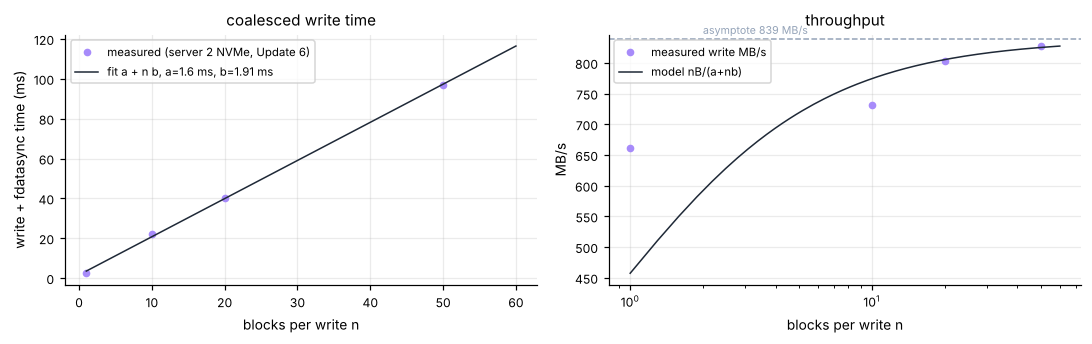

In [4]:
prev_path = ROOT / "benchmarks" / "results" / "test_arch" / "chimera_storage_spill.json"
prev = json.loads(prev_path.read_text())
n = np.array([r["coalesce"] for r in prev["coalesce_results"]], dtype=float)
t_us = np.array([r["write_us"] for r in prev["coalesce_results"]])
Bk = prev["single_block_kb"] * 1024
A = np.vstack([np.ones_like(n), n]).T
(a_us, b_us), *_ = np.linalg.lstsq(A, t_us, rcond=None)
asym = Bk / (b_us * 1e-6) / 1e6
print(f"fit: a = {a_us/1e3:.2f} ms, b = {b_us/1e3:.2f} ms per block, asymptote B/b = {asym:.0f} MB/s")
for ni, ti in zip(n, t_us):
    print(f"  n={ni:3.0f}: measured {ti/1e3:8.2f} ms, model {(a_us + b_us*ni)/1e3:8.2f} ms  ({(ti - a_us - b_us*ni)/ti*100:+.1f}%)")
nn = np.linspace(1, 60, 200)
figf, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(n, t_us / 1e3, "o", color=C["spill"], label="measured (server 2 NVMe, Update 6)"); ax[0].plot(nn, (a_us + b_us * nn) / 1e3, color=C["ink"], lw=1, label=f"fit a + n b, a={a_us/1e3:.1f} ms, b={b_us/1e3:.2f} ms")
ax[0].set_xlabel("blocks per write n"); ax[0].set_ylabel("write + fdatasync time (ms)"); ax[0].legend(); ax[0].set_title("coalesced write time")
ax[1].plot(n, [r["write_mbps"] for r in prev["coalesce_results"]], "o", color=C["spill"], label="measured write MB/s")
ax[1].plot(nn, nn * Bk / ((a_us + b_us * nn) * 1e-6) / 1e6, color=C["ink"], lw=1, label="model nB/(a+nb)"); ax[1].axhline(asym, color=C["muted"], ls="--", lw=1)
ax[1].text(2, asym * 1.01, f"asymptote {asym:.0f} MB/s", fontsize=7, color=C["muted"]); ax[1].set_xscale("log"); ax[1].set_xlabel("blocks per write n"); ax[1].set_ylabel("MB/s"); ax[1].legend(); ax[1].set_title("throughput")
fig("12_coalescing_fit", model=True, caption="least squares on four points; the n=1 miss is the open question in the write-up")

### 1. Functional check: spill, retrieve, corruption detection, free-list reuse

In [5]:
tel = Telemetry()
t = StorageTier(SPILL_DIR, coalesce=4, o_direct=O_DIRECT, telemetry=tel)
print("O_DIRECT:", t.o_direct_reason)
blocks = {f"req7:L{l}": np.random.default_rng(l).integers(0, 256, 50_000, dtype=np.uint8).tobytes() for l in range(10)}
futs = [t.spill(k, v) for k, v in blocks.items()]
t.flush(); [f.result() for f in futs]
assert all(t.retrieve(k).result() == v for k, v in blocks.items())
assert t.retrieve_batch(list(blocks)) == blocks
off = t.extent("req7:L3").offset
with open(t.path, "r+b") as f:
    f.seek(off + 5); f.write(b"\x00" if blocks["req7:L3"][5] else b"\x01")
try:
    t.retrieve("req7:L3").result(); print("corruption NOT detected")
except IntegrityError as e:
    print("corruption detected:", e)
t.delete("req7:L3"); t.spill("small", b"x" * 100); t.flush()
print("reused freed slot:", t.extent("small").offset == off)
print(t.stats())
print("telemetry storage:", {k: v for k, v in tel.snapshot()["classes"]["storage"].items() if k in ("ops", "bytes", "p50_us", "p99_us")})
t.close(remove=True)

O_DIRECT: not requested
corruption detected: crc mismatch for 'req7:L3' at offset 159744
reused freed slot: True
{'path': '/tmp/scuffed-spill/kvspill.bin', 'keys': 10, 'pending': 0, 'file_bytes': 532480, 'used_bytes': 483328, 'free_extents': 1, 'free_bytes': 49152, 'o_direct': False, 'o_direct_reason': 'not requested', 'coalesce': 4, 'batches_written': 4}
telemetry storage: {'ops': 21, 'bytes': 1000100, 'p50_us': 472.1359998711705, 'p99_us': 7396.28399992398}


### 2. Who decides to spill (model figure)

Above the watermark `u0`, spill competes with the hot and cold queues through `sigma_S = delta * q_S * mu_S - gamma * p`. Below it, the two-queue decision is unchanged.

figure -> docs/figures/10_pmp_spill.png  |  three-option bang-bang; the pressure term gamma*p pulls sigma_S below the others as u -> 1


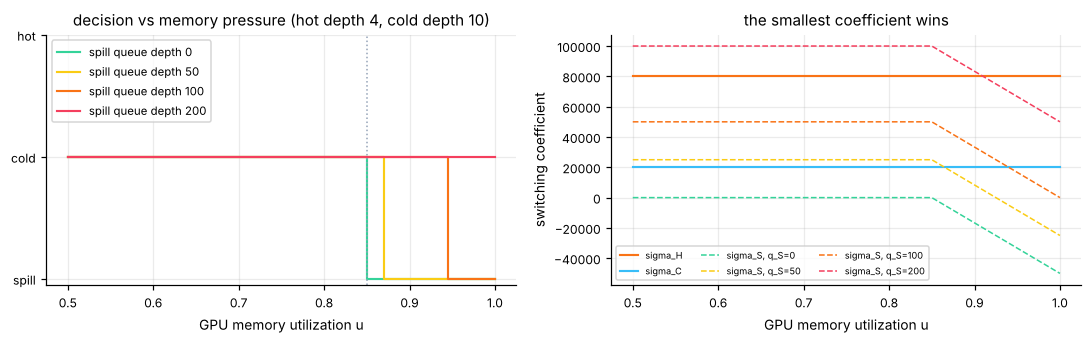

{'gpu_mem_util': 0.6, 'link_util': 0.2} -> cold (rule: prefill-bulk-cold)
{'gpu_mem_util': 0.95, 'link_util': 0.2} -> spill (rule: spill-bulk-under-gpu-pressure)


In [6]:
pmp = PMPController(u0=0.85)
grid_u = np.linspace(0.5, 1.0, 101)
grid_qs = [0, 50, 100, 200]
figs, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for qs, col in zip(grid_qs, (C["ok"], C["gold"], C["hot"], C["bad"])):
    pmp.reset()
    dec = [pmp.decide_with_storage(hot_depth=4, cold_depth=10, gpu_mem_util=u, spill_depth=qs) for u in grid_u]
    ax[0].step(grid_u, [{"hot": 2, "cold": 1, "spill": 0}[d.value] for d in dec], where="post", color=col, label=f"spill queue depth {qs}")
ax[0].set_yticks([0, 1, 2]); ax[0].set_yticklabels(["spill", "cold", "hot"]); ax[0].set_xlabel("GPU memory utilization u"); ax[0].axvline(0.85, color=C["muted"], ls=":", lw=1)
ax[0].set_title("decision vs memory pressure (hot depth 4, cold depth 10)"); ax[0].legend()
u = grid_u; p = np.clip((u - 0.85) / 0.15, 0, None)
ax[1].plot(u, pmp._alpha * 4 * pmp._mu_hot * np.ones_like(u), color=C["hot"], label="sigma_H"); ax[1].plot(u, pmp._beta * 10 * pmp._mu_cold * np.ones_like(u), color=C["cold"], label="sigma_C")
for qs, col in zip(grid_qs, (C["ok"], C["gold"], C["hot"], C["bad"])):
    ax[1].plot(u, pmp._delta * qs * pmp._mu_spill - pmp._gamma * p, color=col, ls="--", lw=1, label=f"sigma_S, q_S={qs}")
ax[1].set_xlabel("GPU memory utilization u"); ax[1].set_ylabel("switching coefficient"); ax[1].set_title("the smallest coefficient wins"); ax[1].legend(ncol=3, fontsize=6, loc="lower left")
fig("10_pmp_spill", model=True, caption="three-option bang-bang; the pressure term gamma*p pulls sigma_S below the others as u -> 1")
eng = PolicyEngine.default_policy()
for ctx in ({"gpu_mem_util": 0.6, "link_util": 0.2}, {"gpu_mem_util": 0.95, "link_util": 0.2}):
    d = eng.decide(SignalVector(size_bytes=8 << 20, role="kv", phase="prefill"), ctx)
    print(ctx, "->", d.route, "(rule:", d.rules["route"] + ")")

### 3. Coalescing sweep (measured)

In [7]:
res = benchmark_coalescing(SPILL_DIR, block_bytes=BLOCK_KB * 1024, coalesce_list=COALESCE, batches=BATCHES,
                           o_direct=O_DIRECT, fsync=FSYNC, block_sizes=[b * 1024 for b in BLOCK_SIZES_KB],
                           meta={"bits": 3, "dim": 128, "seq_len": 256, "heads": 32})
print("O_DIRECT:", res["o_direct"])
for sw in res["sweeps"]:
    print(f"block {sw['single_block_kb']:.0f} KiB")
    for r in sw["coalesce_results"]:
        print(f"  coalesce={r['coalesce']:>3} payload={r['payload_kb']:>9.1f} KiB  write p50={r['write_us']:>9.0f} us "
              f"({r['write_mbps']:>7.1f} MB/s, p99 {r['write_p99_us']:.0f})  read p50={r['read_us']:>9.0f} us ({r['read_mbps']:>7.1f} MB/s)")

O_DIRECT: not requested
block 16 KiB
  coalesce=  1 payload=     16.0 KiB  write p50=      477 us (   34.4 MB/s, p99 1228)  read p50=       22 us (  758.8 MB/s)
  coalesce=  2 payload=     32.0 KiB  write p50=      397 us (   82.5 MB/s, p99 1089)  read p50=       66 us (  494.8 MB/s)
  coalesce=  5 payload=     80.0 KiB  write p50=      562 us (  145.8 MB/s, p99 1006)  read p50=       99 us (  828.3 MB/s)
  coalesce= 10 payload=    160.0 KiB  write p50=      804 us (  203.9 MB/s, p99 1149)  read p50=      254 us (  643.8 MB/s)
  coalesce= 20 payload=    320.0 KiB  write p50=     1420 us (  230.8 MB/s, p99 3480)  read p50=      344 us (  953.8 MB/s)
  coalesce= 50 payload=    800.0 KiB  write p50=     2741 us (  298.8 MB/s, p99 4984)  read p50=     1241 us (  660.3 MB/s)
block 64 KiB
  coalesce=  1 payload=     64.0 KiB  write p50=      471 us (  139.2 MB/s, p99 1202)  read p50=       81 us (  809.4 MB/s)
  coalesce=  2 payload=    128.0 KiB  write p50=      702 us (  186.7 MB/s, p99 15

figure -> docs/figures/local/12_storage_sweep.png  |  local mode: /tmp on this host, not NVMe


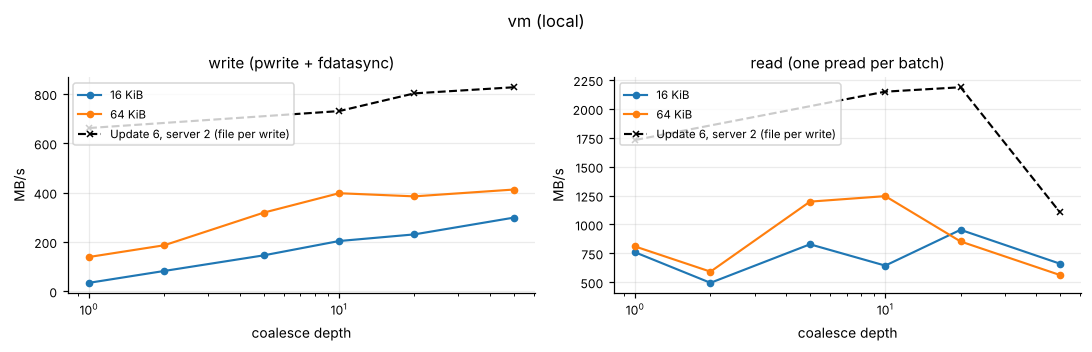

wrote /tmp/scuffed-local/storage_tier/vm_storage_spill.json


PosixPath('/tmp/scuffed-local/storage_tier/vm_storage_spill.json')

In [8]:
figx, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for sw in res["sweeps"]:
    c = [r["coalesce"] for r in sw["coalesce_results"]]
    axes[0].plot(c, [r["write_mbps"] for r in sw["coalesce_results"]], marker="o", label=f"{sw['single_block_kb']:.0f} KiB")
    axes[1].plot(c, [r["read_mbps"] for r in sw["coalesce_results"]], marker="o", label=f"{sw['single_block_kb']:.0f} KiB")
pc = [r["coalesce"] for r in prev["coalesce_results"]]
axes[0].plot(pc, [r["write_mbps"] for r in prev["coalesce_results"]], "k--", marker="x", label="Update 6, server 2 (file per write)")
axes[1].plot(pc, [r["read_mbps"] for r in prev["coalesce_results"]], "k--", marker="x", label="Update 6, server 2 (file per write)")
for ax, t_ in zip(axes, ("write (pwrite + fdatasync)", "read (one pread per batch)")):
    ax.set_xscale("log"); ax.set_xlabel("coalesce depth"); ax.set_ylabel("MB/s"); ax.set_title(t_); ax.legend()
plt.suptitle(f"{HOST} ({MODE})")
fig("12_storage_sweep", caption="local mode: /tmp on this host, not NVMe")
save("storage_spill", {**res, "coalescing_fit_update6": {"a_ms": a_us / 1e3, "b_ms_per_block": b_us / 1e3, "asymptote_MBps": asym}})